In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "10"
os.environ["MKL_NUM_THREADS"] = "10"
os.environ["OPENBLAS_NUM_THREADS"] = "10"
os.environ["NUMEXPR_NUM_THREADS"] = "10"

In [2]:
import time
import matplotlib.pyplot as plt
import numpy as np
from OOPAO.calibration.InteractionMatrix import InteractionMatrix
from OOPAO.tools.displayTools import cl_plot, displayMap
from OOPAO.Source import Source
from OOPAO.Telescope import Telescope
from OOPAO.Atmosphere import Atmosphere
from OOPAO.Detector import Detector
from OOPAO.DeformableMirror import DeformableMirror
from OOPAO.MisRegistration import MisRegistration
from OOPAO.Pyramid import Pyramid
from OOPAO.calibration.compute_KL_modal_basis import compute_KL_basis
from OOPAO.Detector import Detector
from OOPAO.tools.tools import strehlMeter

# number of subaperture for the WFS
n_subaperture = 100

# %%-----------------------     TELESCOPE   ----------------------------------
from OOPAO.Telescope import Telescope

# create the Telescope object
tel = Telescope(resolution           = 400,                          # resolution of the telescope in [pix]
                diameter             = 40,                                        # diameter in [m]        
                samplingTime         = 1/1000,                                   # Sampling time in [s] of the AO loop
                centralObstruction   = 0.3,                                      # Central obstruction in [%] of a diameter 
                display_optical_path = False,                                    # Flag to display optical path
                fov                  = 0 )    


# create the Natural Guide Star object
ngs = Source(optBand     = 'K',           # Optical band (see photometry.py)
             magnitude   = 5,             # Source Magnitude
             coordinates = [0,0])         # Source coordinated [arcsec,deg]

# combine the NGS to the telescope using '*'
ngs*tel

# create the Scientific Target object located at 10 arcsec from the  ngs
src = Source(optBand     = 'I',           # Optical band (see photometry.py)
             magnitude   = 5,              # Source Magnitude
             coordinates = [0,0])        # Source coordinated [arcsec,deg]

# create the Atmosphere object
atm = Atmosphere(telescope     = tel,                                                             
                 r0            = 0.16,                              
                 L0            = 25,                                
                 fractionalR0  = [0.50 ,0.35  ,0.15],
                 windSpeed     = [10   ,10   ,10], 
                 windDirection = [0    ,45   ,180], 
                 altitude      = [0    ,4000 ,10000 ]) 


# initialize atmosphere with current Telescope
atm.initializeAtmosphere(tel)
wfs = Pyramid(nSubap            = n_subaperture,                # number of subaperture = number of pixel accros the pupil diameter
              telescope         = tel,                          # telescope object
              lightRatio        = 0.1,                          # flux threshold to select valid sub-subaperture
              modulation        = 2,                            # Tip tilt modulation radius
            )  
wfs.is_geometric = False
stroke=1e-9

# instrument path
src_cam = Detector(tel.resolution*2)
src_cam.psf_sampling = 4  # sampling of the PSF
src_cam.integrationTime = tel.samplingTime # exposure time for the PSF


# WFS path
ngs_cam = Detector(tel.resolution*2)
ngs_cam.psf_sampling = 4
ngs_cam.integrationTime = tel.samplingTime

# initialize the Strehl Ratio computation
tel.resetOPD()

ngs*tel*ngs_cam
ngs_psf_ref = ngs_cam.frame.copy()
src*tel*src_cam
src_psf_ref = src_cam.frame.copy()







     °          *      *      
 ▄██▄   ▄██▄  ▄███▄   ▄██▄ * ▄██▄ 
██* ██ ██  ██ ██  ██ ██  ██ ██  ██
██  ██ ██° ██ ██  ██ ██* ██ ██  ██
██  ██ ██  ██ ████▀  ██▄▄██ ██  ██
██* ██ ██  ██ ██     ██▀▀██ ██  ██
██  ██ ██  ██ ██ *   ██  ██ ██* ██
 ▀██▀   ▀██▀  ██   ° ██  ██  ▀██▀ 
      *         *             



------------ Telescope -------------
Diameter [m]             |  40.00   
Resolution [px]          |   400    
Pixel size [m]           |   0.10   
Surface [m²]             | 1143.72  
Central obstruction [%]  |    30    
Pixels in pupil          |  114372  
Field of view [arcsec]   |   0.00   
------------------------------------


------------- Source --------------
Source                   |   NGS   
Wavelength [m]           | 2.2e-06 
Zenith [arcsec]          |  0.00   
Azimuth [°]              |  0.00   
Altitude [m]             |   inf   
Magnitude                |  5.00   
Flux [photon/m²/s]       | 1.9e+07 
Coordinates [arcsec,deg] | [0,0]
--------------------------------

In [3]:
from OOPAO.InfluenceFunctions import InfluenceFunctions
IF=InfluenceFunctions(name_system='ELT_M4',
                            diameter=40,
                            resolution=400,
                            loc='/home/msantos/OOPAO/recreate/po4ao/')

dm = DeformableMirror(telescope  = tel,                        # Telescope
                    nSubap       = 39,                     # number of subaperture of the system considered (by default the DM has n_subaperture + 1 actuators to be in a Fried Geometry)
                    mechCoupling = 0.35,                       # Mechanical Coupling for the influence functions
                    modes=IF.influence_function_2D,                     # coordinates in [m]. Should be input as an array of size [n_actuators, 2] 
                    coordinates=IF.coordinates)  

Computing Influence Functions for ELT_M4...
LOADING FEM DATA...

PREPARING COORDINATE SYSTEM INCLUDING DISTORTION...

RUNNING INTERPOLATIONS...

Segment 5  
ELAPSED TIME FOR FEM INTERPOLATION: 20.188721895217896
Coordinates loaded...
Generating a Deformable Mirror: 
Loading the 2D zonal modes...
Done!

-------- Deformable mirror --------
Controlled Actuators     |  5352   
M4                       |  False  
Pitch [m]                |  1.03   
Mechnical coupling [%]   |   35    
== Misregistration ================
Rotation [°]             |  0.000  
Shift X [m]              |0.000e+00
Shift Y [m]              |0.000e+00
Anamorphosis angle [°]   |  0.000  
Tangential scaling [%]   |  0.000  
Radial scaling [%]       |  0.000  
-----------------------------------



In [4]:
from threadpoolctl import threadpool_limits
from OOPAO.calibration.InteractionMatrix import InteractionMatrix

with threadpool_limits(limits=10):
    M2C_KL = compute_KL_basis(tel=tel,atm =atm,dm=dm,lim=0.001)
n_mo=4100
# modal interaction matrix
calib_modal = InteractionMatrix( ngs      = ngs,                    
                                 atm            = atm,                   
                                 tel            = tel,              
                                 dm             = dm,         
                                 wfs            = wfs,            
                                 M2C            = M2C_KL[:,:n_mo],   # M2C matrix to use for the calibratio
                                 stroke         = 1e-9,             # stroke for the calibration in [nm]
                                 nMeasurements  = 4,               # number of measurements in parallel
                                 noise          = 'off',
                                 display=True)            # enable noise during the calibration


TIME ELAPSED: 259 sec. COMPLETED: 100 %
NMAX =  4839
RMS opd error = [[3.42979452e-09 4.30094560e-09 3.62173103e-09]]
RMS Positions = [[0.32348872 0.9473996  0.95010115]]
MAX Positions = [[1.00696997 1.87594721 1.89759582]]
KL WITH DOUBLE DIAGONALISATION: COVARIANCE ERROR =  7.460698725481052e-14


100%|██████████| 1025/1025 [22:33<00:00,  1.32s/it]


In [ ]:
dm.coefs=0
gain=0.5
episode_frames = [] 
delay=2
loop =3000
reconstructor=M2C_KL[:,:n_mo] @ calib_modal.M
wfsSignal = np.arange(0, wfs.nSignal)*0
for i in range(loop):
    atm.update()
    ngs**atm* tel*dm*wfs
    src**atm*tel*dm*src_cam

    if delay == 1:
        wfsSignal = wfs.signal
    
    dm.coefs = dm.coefs - gain* reconstructor @ wfsSignal
    
    if delay == 2:
        wfsSignal = wfs.signal
    #print(strehlMeter(src_cam.frame,tel,src_psf_ref,display=False))
    if i %100==0:
        print(i//100)
    sr  = strehlMeter(src_cam.frame, tel, src_psf_ref, display=False)
    tel.OPD
    episode_frames.append({
            'sr_rc'  : sr,
            'opd':tel.OPD,
            'opd_mr':tel.mean_removed_OPD,
        })
    

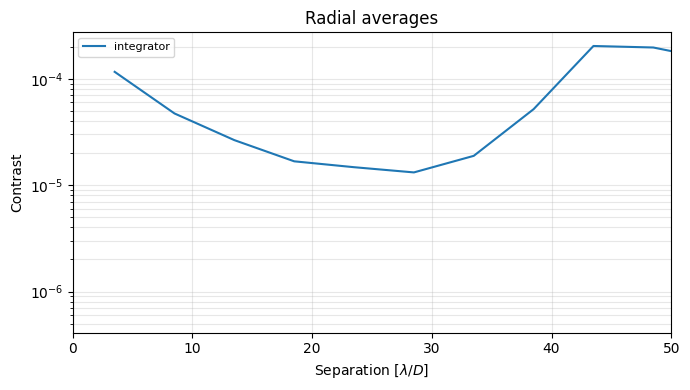

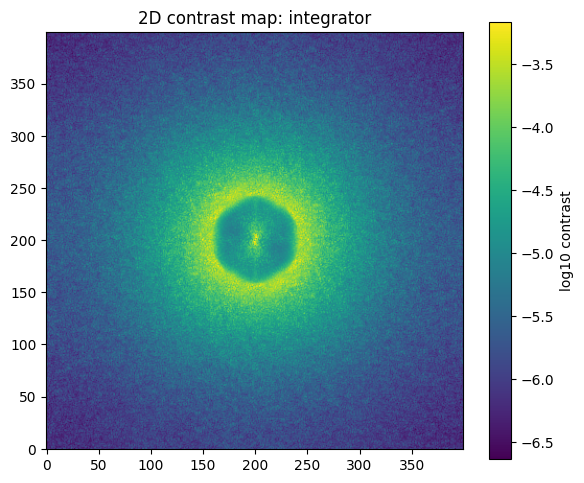

In [29]:
def contrast_curve_from_psd(psd, psd_ref, pix_per_lamD, dr=5):
    import numpy as np
    from scipy.ndimage import map_coordinates

    # ── normalise (same logic as contrast_curve2) ───────────────────────
    psf     = psd     
    psf_ref = psd_ref 
    psf     = psf     / psf_ref.max()          # units: contrast

    ny, nx  = psf.shape
    cy, cx  = ny // 2, nx // 2

    y, x = np.indices(psf.shape)
    r    = np.sqrt((x - cx)**2 + (y - cy)**2)
    max_r = int(r.max())

    # ── 1. Radial median annuli ─────────────────────────────────────────
    contrast_r, radii_r = [], []
    for i in range(1, max_r, dr):
        mask   = (r >= i) & (r < i + dr)
        contrast_r.append(np.median(psf[mask]))
        radii_r.append((i + dr / 2) / pix_per_lamD)

    # ── 2. Horizontal cut ───────────────────────────────────────────────
    h_row    = psf[cy+1, :]
    h_mask   = np.arange(len(h_row)) >= cx
    radii_h  = np.abs(np.arange(len(h_row)) - cx)[h_mask] / pix_per_lamD
    contrast_h = h_row[h_mask]

    # ── 3. Diagonal cut (45°) ───────────────────────────────────────────
    diag_len   = min(cy-1, cx-1)
    steps      = np.arange(1, diag_len)
    contrast_d = psf[(cy + steps).astype(int),
                     (cx + steps).astype(int)]
    radii_d    = (steps * np.sqrt(2)) / pix_per_lamD

    return {
        'radii_r'    : np.array(radii_r),
        'contrast_r'  : np.array(contrast_r),
        'radii_h'    : radii_h,
        'contrast_h'  : contrast_h,
        'radii_d'    : radii_d,
        'contrast_d'  : contrast_d,
    }

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal.windows import hann
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal.windows import hann

lastN = 2500
SCALE = 8e17                      
key = 'opd_mr'                 

dx = tel.D / tel.resolution
N, M = tel.OPD.shape
w = np.outer(hann(N), hann(M))
w2_sum = np.sum(w**2)
psd_lists = []

for fr in episode_frames[-lastN:]:
    opd = np.array(fr[key], dtype=float)
    F     = np.fft.fftshift(np.fft.fft2(opd * w))
    psd2d = (np.abs(F)**2) * (dx**2) / w2_sum
    psd_lists.append(psd2d)

psd_mean = np.mean(psd_lists,axis=0)
pix_per_lamD = N * dx / tel.D

curves = contrast_curve_from_psd(psd_mean * SCALE, src_psf_ref, pix_per_lamD, dr=5)

fig, ax = plt.subplots(figsize=(7, 4))

ax.semilogy(curves['radii_r'], curves['contrast_r'], lw=1.5, label="integrator")
ax.set_title('Radial averages')
ax.set_xlabel(r'Separation [$\lambda/D$]')
ax.set_ylabel('Contrast')
ax.set_xlim(0, 50)
ax.legend(fontsize=8)
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

img = np.log10(psd_mean * SCALE / src_psf_ref.max())

fig2, ax2 = plt.subplots(figsize=(6, 5))
im = ax2.imshow(img, origin='lower', cmap='viridis')
ax2.set_title(f'2D contrast map: integrator')
ax2.grid(False)
plt.colorbar(im, ax=ax2, label='log10 contrast')
plt.tight_layout()
plt.show()